# _K_-Means from scratch

We have learned about the _K_-Means algorithm, and some of its variants in earlier chapters. In this programming notebook, we are going to implement a previous concept programmatically from scratch. 


## Learning Objective

After completing this programming notebook, students should be able to:

* Implement KMeans from scratch for a given dataset.

* Examine the effect of outlier in KMeans and implement its variant to solve it then analyze the output.

* Interpret the goodness of the cluster by between cluster distance and validate it by visualizing.

* Implement different centroid initialization methods and analyze its effect.


First of all, let's import some of the common libraries we will be using very often.

## Common Libraries

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
np.random.seed(100) # change seed value and see for different random init

plt.rcParams['figure.figsize'] = (10, 5)

## **Generate Synthetic Datasets**

To implement the _K_-Means algorithm and show the working process, we will generate some synthetic dataset using the `sklearn`'s datasets module.

In [ ]:
from sklearn.datasets import make_blobs

n_samples = 100  # number of samples to generate
random_state = 100  # seed value

## Generate noisy data points
X_noisy, _ = make_blobs(
    n_samples=n_samples,
    random_state=random_state,
    cluster_std=[1.5, 1, 1, 10],
    centers=4,
)

## Generate clean data points
X_clean, _ = make_blobs(
    n_samples=n_samples, random_state=random_state, cluster_std=[1.5, 1, 1], centers=3
)

print(X_clean.shape, X_noisy.shape)


(100, 2) (100, 2)


Above, we generated two kinds of data sets. In the first `X_noisy` dataset, we are creating 3 clusters with low standard deviation, and for the fourth cluster, we are setting the high standard value to act as a noise. 

Similarly, for the second `X_clean` dataset, we are creating 3 clusters with a low standard deviation like the first one.

In [ ]:
# CODE BLOCK 1

def plot_data(
    x,
    centers=None,
    belongto=None,
    color_list=list([]),
    ax=plt,
    y_label="feature 2",
    x_label="feature 1",
    title="KMeans",
):
    """Wrapper to plot data points, centroids if available and the respective region


    Parameters:
        - x: all the features from the dataset
        - centers: centers of the cluster
        - belongto: predicted values from the model
        - color_list: list of colors for hue
        - ax: pass the i^th plot if subplot else default matplotilib's pyplot is used
        - y_label: label for y axis
        - x_label: label for x axis
        - title: title for the plot

    Returns: 
        None 

    """
    ax.scatter(
        x[:, 0],
        x[:, 1],
        s=5,
        lw=10,
        c=belongto if belongto is not None else "black",
        cmap=matplotlib.colors.ListedColormap(color_list),
    ) # Scatter plot of data points

    ## use set_ if subplot else use normal label
    try:
        ax.set_ylabel(y_label)
        ax.set_xlabel(x_label)
        ax.title.set_text(title)
    except:
        ax.ylabel(y_label)
        ax.xlabel(x_label)
        ax.title(title)

    ## if centers are availeble, plot them
    if centers is not None:
        ax.scatter(
            centers[:, 0],
            centers[:, 1],
            marker="X",
            c=color_list,
            s=200,
            edgecolors="black",
        )

Above, we have created a helper function that helps us plot our data points and the cluster centers in one go to reduce the redundancy. 

Let's see our function in action. We are going to plot our noisy and clean datasets in a subplot.

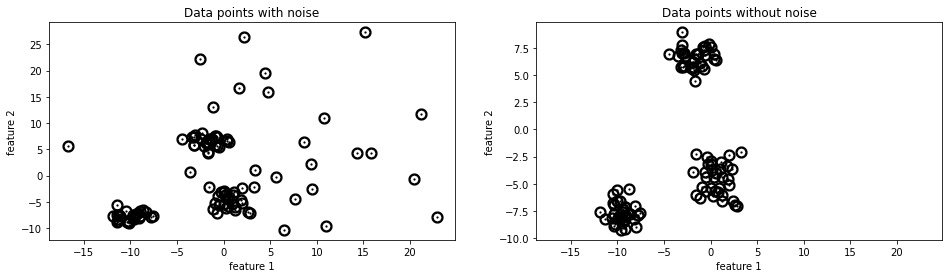

In [ ]:
## Subplot for 2 datasets
fig, ax_arr = plt.subplots(ncols=2, figsize=(16,4), sharex=True)

plot_data(X_noisy, ax=ax_arr[0], title="Data points with noise" )
plot_data(X_clean, ax=ax_arr[1], title="Data points without noise")
fig.show()

As you can see above, we have noisy data on the left side and the clean one on the right side. Now, we will build a KMeans model to compare its performance on noisy and clean datasets.

## _K_-Means from Scratch

In [ ]:
## Custom KMeans from scratch

class KMeans:
    
    def __init__(
        self, n_centers=3, init="random", distance_metric="l2", threshold=1e-4,
    ):
        self.n_centers = n_centers
        self.threshold = threshold
        self.data = None  # array with shape (100 samples, 2 features)
        self.centers = None  # array with shape (n_centers, 2)
        self.prev_centers = None  # array with shape (n_centers, 2)
        self.data_cluster = None  # array with shape (100, )
        self.distances = None  # array with shape (n_centers, 100)
        self.distance_metric = distance_metric
        self.init = init
        self.n_dim = None
        # self.max_iter = 1

    def fit(self, data):
        """ Initialize data for training

        Parameters:
            data: input features of shape (100, 2)

        """
        self.data = data
        self.n_dim = self.data.shape[-1]

        if self.init == "kmeans++":
            self.centers = self._generate_kmeans_plus_centers()
        elif self.init == "uniform":
            self.centers = self._generate_uniform_centers()
        else:
            self.centers = self._generate_random_sampled_centers()

    def _generate_kmeans_plus_centers(self):
        """KMeans++ initialization"""

        centers = []
        X = self.data

        ## Sample the first point at random
        initial_index = np.random.choice(range(X.shape[0]),)
        centers.append(np.asarray(X[initial_index, :].tolist()))

        ## Loop and select the remaining points
        for i in range(self.n_centers - 1):
            distance = np.sum((np.array(centers) - X[:, None, :])**2, axis = 2)

            if i == 0:
                pdf = distance / np.sum(distance)
                centroid_new = X[
                    np.random.choice(range(X.shape[0]), replace=False, p=pdf.flatten())
                ]
            else:
                ## Calculate distance of each point from its nearest centroid
                dist_min = np.min(distance, axis=1)

                pdf = dist_min / np.sum(dist_min)

                ## Sample one point from the given prob distribution
                centroid_new = X[np.random.choice(range(X.shape[0]), replace=False, p=pdf)]

            centers.append(centroid_new.tolist())

        return np.array(centers)

    def _generate_uniform_centers(self):
        """Generate uniform centers"""

        centers = np.random.uniform(
            low=self.data.min(axis=0),
            high=self.data.max(axis=0),
            size=(self.n_centers, self.n_dim),
        )
        return centers

    def _generate_random_sampled_centers(self):
        """Generate random sampled centers"""

        rand_index = np.random.randint(
            low=0, high=self.data.shape[0], size=self.n_centers
        )

        centers = self.data[rand_index]
        return centers

    def _l2(self, point1, point2):
        """Euclidean distance"""

        diff = point1 - point2
        sqrd = np.square(diff)
        sumd = np.sum(sqrd, axis=1)
        sqrt = np.sqrt(sumd)
        return sqrt

    def _l1(self, point1, point2):
        """Absolute distance"""

        diff = point1 - point2
        _abs = np.abs(diff)
        sumd = np.sum(_abs, axis=1)
        return sumd

    def _calculate_distance(self):
        """Wrapper for calculating distance with data and center"""

        dist = []
        for center in self.centers:
            if self.distance_metric == "l1":
                abd = self._l1(self.data, center)
                dist.append(abd)
            else:
                sqrt = self._l2(self.data, center)
                dist.append(sqrt)  # collecting all the sum

        self.distances = np.array(dist)
        return self.distances

    def _assign_clusters(self):
        """Assign each data sample to small distanced centroid"""

        self.data_cluster = np.argmin(
            self.distances, axis=0
        )  # finding minimum over the the centers

        return self.data_cluster

    def _update_centers(self):
        """Update centers with new mean among the cluster"""

        self.prev_centers = np.copy(self.centers)

        for i in range(self.n_centers):
            self.centers[i] = np.mean(
                self.data[self.data_cluster == i], axis=0
            )  # mean among the row: axis=0
        return self.centers

    def converge(self):
        """ Training convergence"""

        self._calculate_distance()
        self._assign_clusters()
        self._update_centers()

    def is_optimal(self):
        """ Check if the centers are optimal."""

        non_optimal = np.abs(self.prev_centers - self.centers) > self.threshold
        if non_optimal.astype(int).sum() == 0:
            return True
        return False

Above we have created a `KMeans` class which takes a number of centers(`n_centers`), initialization method (`init`), distance metric(`distance_metric`), and the threshold value (`threshold`) as an input. We have built various private methods to perform the internal operations like centroid initializing, computing distances, and public methods like `fit`, `converge`, and `is_optimal` to train and evaluate the model.  


Now let's build a `KMeans` model for our noisy and clean datasets using random initialization(We have created a method for different random initializations. You can try out the random sampling or uniform sampling). 

**Important:** Before moving any further, it is worth noting that we are not going to learn how to choose the value for `K`. We have learned that in our L1 KMeans and here, we are just going to see how we can implement a _K_-Means algorithm from scratch. You can run the elbow method on the `KMeans` class by yourself to see which best `K` it outputs. We evaluate the goodness of the cluster by using between cluster distance w.r.t given threshold in the `is_optimal` method and visualizing the clusters.

In [ ]:
## number of clusters
n_clusters = 3

## Noisy KMeans
kmeans_random = KMeans(
    n_centers=n_clusters, init="random", distance_metric="l2"
)
kmeans_random.fit(X_noisy)

## Clean KMeans 
kmeans_random_clean = KMeans(
    n_centers=n_clusters, init="random", distance_metric="l2"
)
kmeans_random_clean.fit(X_clean)

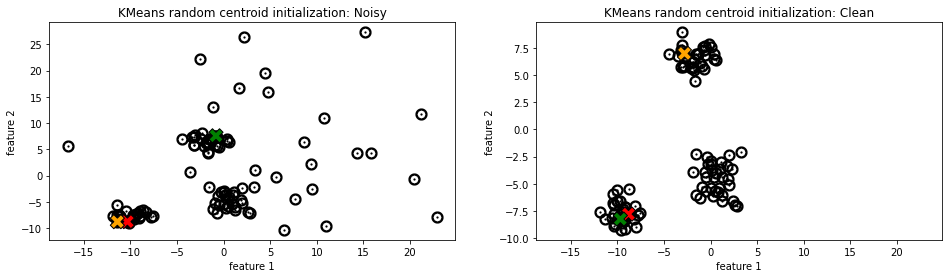

In [ ]:
# CODE BLOCK 2

color_list = ["r", "g", "orange", "plum", "teal"][:n_clusters]

## Subplots for clean and noisy datasets
fig, ax_arr = plt.subplots(ncols=2, figsize=(16,4), sharex=True)

plot_data(
    X_noisy,
    kmeans_random.centers,
    color_list=color_list,
    ax=ax_arr[0],
    title="KMeans random centroid initialization: Noisy",
)

plot_data(
    X_clean,
    kmeans_random_clean.centers,
    color_list=color_list,
    ax=ax_arr[1],
    title="KMeans random centroid initialization: Clean",
)

fig.show()

As you can see above, we have got our initial random cluster centroids. Now we have to converge these centroids to fit the clusters.

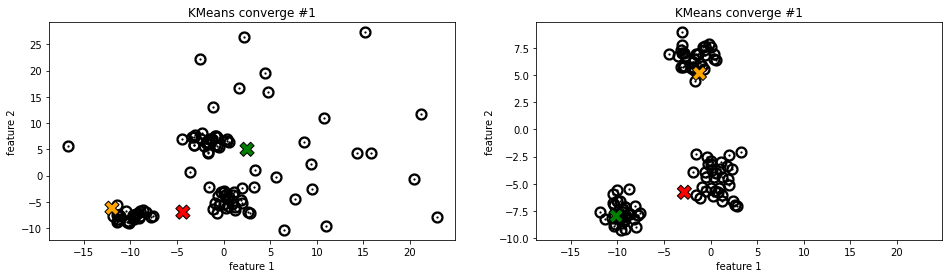

In [ ]:
fig, ax_arr = plt.subplots(ncols=2, figsize=(16,4), sharex=True)

kmeans_random.converge()

plot_data(
    X_noisy, kmeans_random.centers, color_list=color_list, title="KMeans converge #1", ax=ax_arr[0]
)

kmeans_random_clean.converge()
plot_data(
    X_clean, kmeans_random_clean.centers, color_list=color_list, title="KMeans converge #1", ax=ax_arr[1]
)
fig.show()

Above shown in the result of the first convergence of our KMeans. We can check if the centroids are optimal or not by using our `is_optimal` method.

Let's iteratively run our algorithm until it is optimal using a while loop. Since we have a small dataset and the convergence of KMeans is guaranteed, we use the while loop. You can also run it using the loop on a predefined number of iteration steps. 

In [ ]:
while not kmeans_random.is_optimal():
  kmeans_random.converge()

while not kmeans_random_clean.is_optimal():
  kmeans_random_clean.converge()

Now that we have got the optimal centroids let's visualize our clusters.

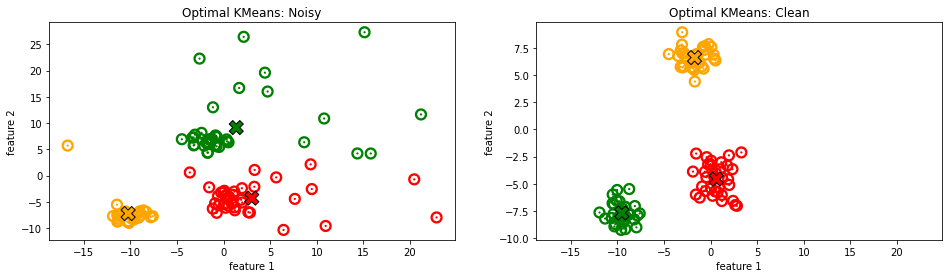

In [ ]:
# CODE BLOCK 3
fig, ax_arr = plt.subplots(ncols=2, figsize=(16,4), sharex=True)


plot_data(
    X_noisy,
    kmeans_random.centers,
    kmeans_random.data_cluster,
    color_list=color_list,
    ax=ax_arr[0],
    title="Optimal KMeans: Noisy",
)


plot_data(
    X_clean,
    kmeans_random_clean.centers,
    kmeans_random_clean.data_cluster,
    color_list=color_list,
    ax=ax_arr[1],
    title="Optimal KMeans: Clean",
)
fig.show()

As you can see above, our KMeans on noisy data have distorted shapes, but in clean data, it has converged nicely. This shows the effect of the outlier in KMeans. We can see that our cluster centroids are pulled toward the outliers.

To overcome this problem, let's try using the `median` variant instead of `mean` and `l1` distance metric instead of `l2`.

In [ ]:

class KMedian(KMeans):
    """kMedian variant built on top of KMeans"""

    def __init__(self, n_centers, init, distance_metric):

        super(KMedian, self).__init__(n_centers, init, distance_metric)

    def _update_centers(self):
        self.prev_centers = np.copy(self.centers)

        for i in range(self.n_centers):

            self.centers[i] = np.median(
                self.data[self.data_cluster == i], axis=0
            )  # median among the row .: axis=0
        return self.centers


In [ ]:
## number of clusters
n_clusters = 3

## Noisy KMedian
kmedian = KMedian(
    n_centers=n_clusters, init="random", distance_metric="l1"
)
kmedian.fit(X_noisy)

## Clean KMedian 
kmedian_clean = KMedian(
    n_centers=n_clusters, init="random", distance_metric="l1"
)
kmedian_clean.fit(X_clean)

In [ ]:
kmedian.converge()
kmedian_clean.converge()


while not kmedian.is_optimal():
  kmedian.converge()

while not kmedian_clean.is_optimal():
  kmedian_clean.converge()

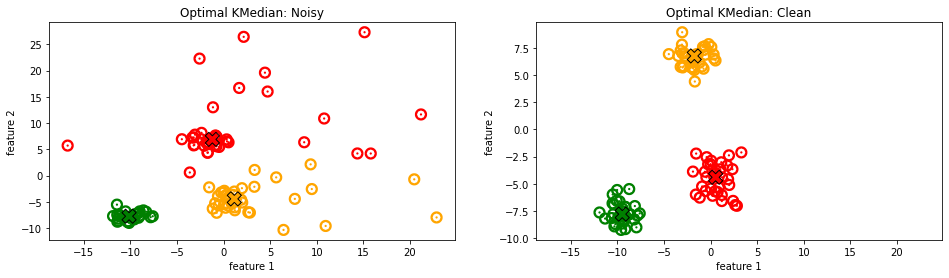

In [ ]:
# CODE BLOCK 4

fig, ax_arr = plt.subplots(ncols=2, figsize=(16,4), sharex=True)


plot_data(
    X_noisy,
    kmedian.centers,
    kmedian.data_cluster,
    color_list=color_list,
    ax=ax_arr[0],
    title="Optimal KMedian: Noisy",
)


plot_data(
    X_clean,
    kmedian_clean.centers,
    kmedian_clean.data_cluster,
    color_list=color_list,
    ax=ax_arr[1],
    title="Optimal KMedian: Clean",
)
fig.show()

You can see that our `median` variant performed well in both cases. We have got a nice cluster in our noisy dataset as well.




## Centroid Initializations

Now that we have implemented and seen the output of _K_-Means and Median variant of _K_-Means, let's see the effect of the centroid initialization method. You can see in the model initialization above, up to now, we are just using the random initialization method. We have built a method for `KMeans++` initialization method as well.

We learned about `KMeans++` earlier, now here we will see the same `KMeans++` in action.

In [ ]:
## number of clusters
n_clusters = 3

## Noisy KMeans
kmeans_plus = KMeans(
    n_centers=n_clusters, init="kmeans++", distance_metric="l2"
)
kmeans_plus.fit(X_noisy)

## Clean KMeans 
kmeans_plus_clean = KMeans(
    n_centers=n_clusters, init="kmeans++", distance_metric="l2"
)
kmeans_plus_clean.fit(X_clean)

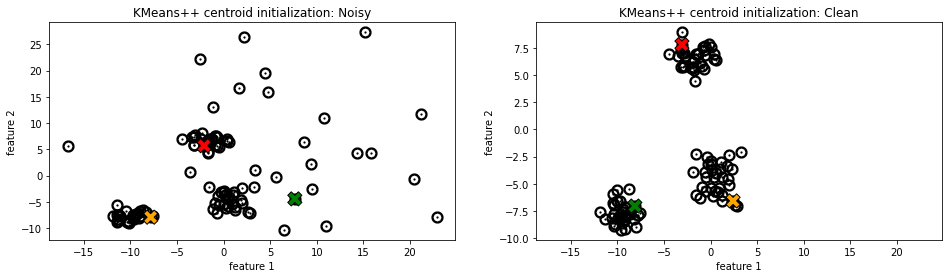

In [ ]:

color_list = ["r", "g", "orange", "plum", "teal"][:n_clusters]

## Subplots for clean and noisy datasets
fig, ax_arr = plt.subplots(ncols=2, figsize=(16,4), sharex=True)

plot_data(
    X_noisy,
    kmeans_plus.centers,
    color_list=color_list,
    ax=ax_arr[0],
    title="KMeans++ centroid initialization: Noisy",
)

plot_data(
    X_clean,
    kmeans_plus_clean.centers,
    color_list=color_list,
    ax=ax_arr[1],
    title="KMeans++ centroid initialization: Clean",
)

fig.show()

You can see that `kmeans++` centroid initialization is different than the random initialization we did earlier. KMeans++ is sensitve to outliers but for clean data it does fine job. Now since we have a better initialization in clean data, our algorithm can converge in early few steps. You can validate it yourself by running the `kmeans_plus.converge()` method with a predefined max iteration loop.